# 19 — CartPole: Async Vector Rollout + A2C

N개 환경은 별도 Process에서 실행하지만, 하나의 정책으로 T Step을 수집한 뒤 **동기적으로 한 번** 업데이트한다. A3C가 아니다.
기존 `18_actor_critic.ipynb`의 즉시 B=1 학습은 유지한다. 이번에는 `B.Rollout`, `T.RolloutReturn`, `L.A2C`를 직접 조합한다.
GAE/PPO와 범용 Runner는 구현하지 않는다.

In [1]:
from pathlib import Path
import os, sys, json
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').exists())
if str(root) not in sys.path: sys.path.insert(0, str(root))
import gymnasium as gym
from gymnasium.vector import AsyncVectorEnv, AutoresetMode
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
from modular_rl import Model, representations as R, estimators as E, selectors as S
from modular_rl import buffers as B, targets as T, updates as U, learners as L
from modular_rl.environment import validate_vector_env, final_observations
from notebooks.gymnasium.tutorial_utils import evaluate, history, record

FAST = os.environ.get('MODULARRL_FAST', '0') == '1'
SEED, GAMMA = 7, .99
N_ENVS, HORIZON = 4, 5
STEP_BUDGET = 400 if FAST else 80000  # individual environment transitions
assert STEP_BUDGET % (N_ENVS * HORIZON) == 0
torch.manual_seed(SEED)
torch.set_num_threads(1)
plt.close('all')
print({'mode':'FAST' if FAST else 'FULL', 'seed':SEED, 'n_envs':N_ENVS,
       'horizon':HORIZON, 'environment_steps':STEP_BUDGET, 'device':'cpu'})

Matplotlib is building the font cache; this may take a moment.


{'mode': 'FULL', 'seed': 7, 'n_envs': 4, 'horizon': 5, 'environment_steps': 80000, 'device': 'cpu'}


## SAME_STEP의 두 관측

Gymnasium >=1.1의 `AutoresetMode.SAME_STEP`을 명시한다(검증 환경: 1.4.0).
종료된 환경의 `step()` 반환 관측은 **새 Episode의 Reset 관측**이다. 이는 다음 행동 선택에 사용한다.
이전 전이의 `next_observation`에는 `info['final_obs']`와 `_final_obs` Mask를 확인한 실제 마지막 관측을 넣는다.

`validate_vector_env`는 Box 관측·0부터 시작하는 Discrete 행동과 SAME_STEP을 검사한다.
NEXT_STEP은 Reset-only 반환을 경험으로 넣을 위험이 있어 거절한다.
[Gymnasium 공식 Autoreset 설명](https://farama.org/Vector-Autoreset-Mode).

|값|Shape|의미|
|---|---|---|
|환경 관측 / 행동|`(N,4)` / `(N,)`|N개 실제 Step|
|Rollout 관측 / 실제 다음 관측|`(T,N,4)`|시간 우선, 독립 Snapshot|
|Reward·경계·V·log_prob|`(T,N)`|경계별 Episode 구분|

Buffer는 환경과 Return 수식을 모르며 get 이후 clear해서 재사용한다. V/log_prob은 수집 시점의 graph 없는 CPU 복사본이다.

In [2]:
model = Model(
    R.MLP(4, hidden_dims=(64,), activation=nn.Tanh),
    E.ActorCritic(E.CategoricalPolicy(64,2), E.StateValue(64)), S.Categorical(),
)
model.eval()  # eval does not disable gradients; keeps collection/re-evaluation consistent
optimizer = torch.optim.Adam(model.parameters(), lr=.001)
buffer = B.Rollout(horizon=HORIZON, n_envs=N_ENVS)
target_generator = T.RolloutReturn(GAMMA)
update_rule = U.ActorCritic(value_coef=.5, entropy_coef=.01)
learner = L.A2C(model, optimizer, target_generator, update_rule)
with gym.make('CartPole-v1') as eval_env:
    before = evaluate(eval_env, lambda obs: model.act(obs, deterministic=True).action.item(),
                      episodes=3 if FAST else 20, seed=SEED+1000)
print('before mean return', float(np.mean(before['rewards'])))

before mean return 9.2


## Multi-step Return과 Gradient

연속 구간은 `G_t = r_t + gamma G_(t+1)`이다. Rollout 끝에서는 실제 다음 관측의 V를 사용한다.
자연 종료는 `G_t=r_t`, Truncation-only는 `G_t=r_t+gamma V(final_obs)`로 시작하며 다음 Episode의 Reward와 연결하지 않는다.
따라서 Bootstrap Mask `~terminated`와 Reward Trace 경계 `terminated | truncated`는 다르다.

T Step을 수집하는 동안 파라미터를 바꾸지 않는다. Learner는 현재 Policy/V를 재평가하고
`U.ActorCritic`에 T×N개 표본을 전달해 평균 Loss로 한 번 학습한다.
Actor의 Advantage만 detach하며 Critic은 미분한다. 저장한 log_prob은 Actor Gradient의 원천이 아니다.
Snapshot 비교는 감지 가능한 정책 변경을 거절하지만 모든 파라미터 변경을 증명하지는 않는다.
Dropout/BatchNorm을 쓰면 수집과 재평가에서 일관된 eval Forward를 사용한다.

In [3]:
log = history()
episode_steps, losses, actor_losses, critic_losses, entropies, td_errors, updates = [], [], [], [], [], [], []
totals, lengths = np.zeros(N_ENVS), np.zeros(N_ENVS, dtype=np.int64)
environment_steps = 0
env = AsyncVectorEnv(
    [lambda: gym.make('CartPole-v1', max_episode_steps=60 if FAST else 500) for _ in range(N_ENVS)],
    context='spawn', copy=True, autoreset_mode=AutoresetMode.SAME_STEP,
)
try:
    validate_vector_env(env)
    observation, _ = env.reset(seed=[SEED+i for i in range(N_ENVS)])
    for update_index in range(STEP_BUDGET // (N_ENVS * HORIZON)):
        for _ in range(HORIZON):
            with torch.no_grad():
                estimate = model(observation)
                selected = model.action_selector.select(estimate)  # same selector as Model.act; one forward also supplies V
            returned, reward, terminated, truncated, info = env.step(selected.action.cpu().numpy())
            actual_next = final_observations(returned, terminated, truncated, info)
            buffer.add(observation, selected.action, reward, actual_next, terminated, truncated,
                       value=estimate.values.v, log_prob=selected.log_prob)
            environment_steps += N_ENVS
            totals += reward; lengths += 1
            for index in np.flatnonzero(terminated | truncated):
                record(log, float(totals[index]), int(lengths[index]), bool(terminated[index]), bool(truncated[index]))
                episode_steps.append(environment_steps)
                totals[index] = 0.; lengths[index] = 0
            observation = returned  # reset states for the NEXT action, not previous bootstrap

        rollout = buffer.get()
        if update_index == STEP_BUDGET // (N_ENVS * HORIZON)-1:
            # Inspect the final rollout with the existing generator, before updating.
            with torch.no_grad():
                next_value = model(rollout.next_observation.flatten(0,1)).values.v.reshape(HORIZON,N_ENVS)
                returns = target_generator.generate(rollout.reward.float(), next_value,
                                                    rollout.terminated, rollout.truncated)
        result = learner.learn(rollout)  # exactly one optimizer step for T*N fresh samples
        advantages = result.td_error
        losses.append(result.total_loss.item()); actor_losses.append(result.actor_loss.item())
        critic_losses.append(result.critic_loss.item()); entropies.append(result.entropy.item())
        td_errors.append(result.td_error.abs().mean().item()); updates.append(environment_steps)
        buffer.clear()
        if (update_index+1) % (10 if FAST else 500) == 0:
            print('update', update_index+1, 'environment steps', environment_steps,
                  'episodes', len(log['rewards']), 'recent return', round(float(np.mean(log['rewards'][-20:])),2),
                  'loss', round(losses[-1],4))
except BaseException:
    env.close(terminate=True)  # also close surviving workers after an exception
    raise
finally:
    env.close()
print('rollout / return / advantage shapes', tuple(rollout.observation.shape), tuple(returns.shape), tuple(advantages.shape))
print('last returns', returns)
print('last advantages', advantages)
print('unfinished episode lengths', lengths.tolist())

update 500 environment steps 10000 episodes 579 recent return 41.4 loss 3.2587


update 1000 environment steps 20000 episodes 774 recent return 43.35 loss 2.0358


update 1500 environment steps 30000 episodes 894 recent return 63.7 loss 59.6491


update 2000 environment steps 40000 episodes 966 recent return 182.65 loss 101.2267


update 2500 environment steps 50000 episodes 1038 recent return 149.0 loss 1.105


update 3000 environment steps 60000 episodes 1105 recent return 176.1 loss 1.2997


update 3500 environment steps 70000 episodes 1168 recent return 185.55 loss 0.1847


update 4000 environment steps 80000 episodes 1231 recent return 165.2 loss 0.6038
rollout / return / advantage shapes (5, 4, 4) (5, 4) (5, 4)
last returns tensor([[66.6311, 66.9666, 69.4565, 60.6196],
        [66.2941, 66.6329, 69.1480, 60.2218],
        [65.9536, 66.2959, 68.8363, 59.8200],
        [65.6097, 65.9554, 68.5215, 59.4142],
        [65.2623, 65.6116, 68.2036, 59.0042]])
last advantages tensor([[ 1.4722,  0.6316,  1.9978,  1.6158],
        [ 1.3008,  0.9235,  1.2504,  0.9266],
        [ 0.8446,  0.1911,  0.9782,  0.6161],
        [ 0.8719, -0.2005,  1.1968,  0.6843],
        [ 0.2770, -0.3312,  0.4252,  0.2090]])
unfinished episode lengths [82, 233, 404, 153]


In [4]:
with gym.make('CartPole-v1') as eval_env:
    after = evaluate(eval_env, lambda obs: model.act(obs, deterministic=True).action.item(),
                     episodes=3 if FAST else 20, seed=SEED+1000)
summary = dict(before=float(np.mean(before['rewards'])), after=float(np.mean(after['rewards'])),
               episodes=len(log['rewards']), environment_steps=environment_steps,
               vector_steps=environment_steps//N_ENVS, gradient_updates=len(losses),
               samples_per_update=N_ENVS*HORIZON, data_passes=1, n_envs=N_ENVS, horizon=HORIZON,
               gamma=GAMMA, learning_rate=.001, value_coef=update_rule.value_coef,
               entropy_coef=update_rule.entropy_coef, seed=SEED)
print('RESULT', json.dumps(summary, sort_keys=True))

RESULT {"after": 465.55, "before": 9.2, "data_passes": 1, "entropy_coef": 0.01, "environment_steps": 80000, "episodes": 1231, "gamma": 0.99, "gradient_updates": 4000, "horizon": 5, "learning_rate": 0.001, "n_envs": 4, "samples_per_update": 20, "seed": 7, "value_coef": 0.5, "vector_steps": 20000}


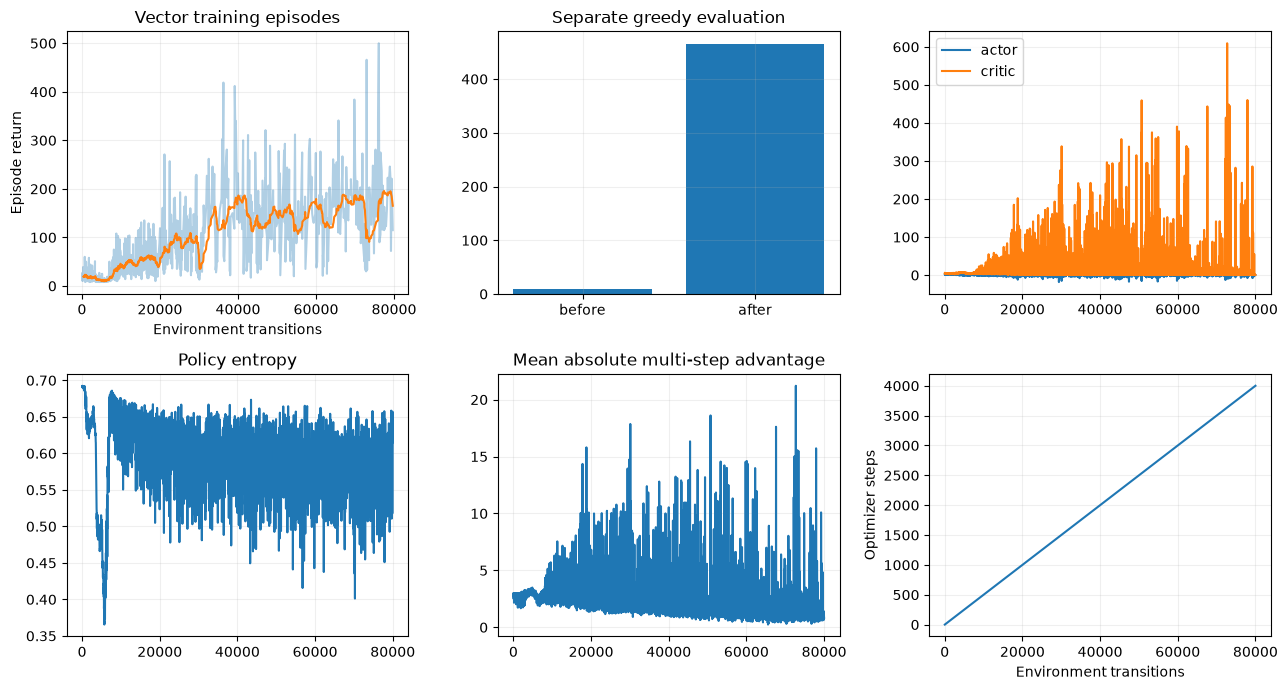

In [5]:
fig, axes = plt.subplots(2,3,figsize=(13,7))
rewards = np.asarray(log['rewards']); window = min(20,len(rewards))
moving = np.convolve(rewards,np.ones(window)/window,mode='valid')
axes[0,0].plot(episode_steps,rewards,alpha=.35)
axes[0,0].plot(episode_steps[window-1:],moving)
axes[0,0].set(xlabel='Environment transitions',ylabel='Episode return',title='Vector training episodes')
axes[0,1].bar(['before','after'],[summary['before'],summary['after']]); axes[0,1].set_title('Separate greedy evaluation')
axes[0,2].plot(updates,actor_losses,label='actor'); axes[0,2].plot(updates,critic_losses,label='critic'); axes[0,2].legend()
axes[1,0].plot(updates,entropies); axes[1,0].set_title('Policy entropy')
axes[1,1].plot(updates,td_errors); axes[1,1].set_title('Mean absolute multi-step advantage')
axes[1,2].plot(updates,np.arange(1,len(updates)+1)); axes[1,2].set(xlabel='Environment transitions',ylabel='Optimizer steps')
for ax in axes.flat: ax.grid(alpha=.2)
fig.tight_layout(); plt.show()

## 18 Actor-Critic과의 비교

동일한 Tanh MLP(64), Adam(.001), gamma=.99와 Loss 계수를 사용한다.
18은 환경 경험 하나마다 B=1로 즉시 업데이트하고, 19는 N=4,T=5의 20개 새 경험마다 한 번 업데이트한다.
FULL 예산은 둘 다 80,000개 환경 전이다. 업데이트는 각각 80,000회 / 4,000회이며, 경험은 각각 한 번만 사용한다.
환경 Seed와 정책 진화가 다르므로 같은 경험을 본다는 뜻은 아니다. 수집 Process의 병렬성과 학습의 동기성도 구분한다.

FULL 실험 결과와 18의 별도 재실행 결과는 `docs/ARCHITECTURE.md`의 최신 A2C 절에 기록한다.
FAST는 연결·경계·재현성 확인용이며, 특정 보상 500 달성을 pytest 합격 조건으로 삼지 않는다.

## 다음 확장과 제약

관측, 선택 행동, 당시 V/log_prob, 실제 다음 관측과 두 경계 Mask는 향후 GAE/PPO에 재사용할 수 있다.
GAE의 lambda Trace와 PPO의 Ratio/Clipping/Minibatch는 아직 없다. NEXT_STEP의 reset-only 반환이나
환경별 유효 길이를 더미 전이로 채우지 않는다. Recurrent state, 연속 행동, 부분 Rollout도 이번 범위 밖이다.
Checkpoint는 Model/Optimizer와 수집 RNG·진행 상태를 함께 보존한다. 업데이트 중간의 Rollout만 복원해서 정책 최신성을 보장할 수는 없다.

이번 별도 FULL 실행 기록(Seed 7, 동일 평가 Seed 20개):

|Learner|환경 전이|Optimizer Step|평가 평균 전 → 후|
|---|---:|---:|---:|
|18: 1-step AC 재실행|80000|80000|9.20 → 500.00|
|19: A2C N=4,T=5|80000|4000|9.20 → 465.55|

이 표는 FAST 실행 결과가 아니며, 단일 Seed의 측정 기록이다. 현재 실행 결과는 위 RESULT 출력을 따른다.